In [1]:
"""
mPING observation-sample characterization for the AI-NWP ptype verification.

Sample definition (matches the verification pairing):
  * valid times 2021-12-01 00Z .. 2022-03-31 18Z
  * synoptic hours only (00, 06, 12, 18 UTC); each mPING timestamp is treated
    as the forecast valid time and matched exactly to AI-NWP output
  * counting unit = observation (one RAP grid cell x one valid time), which is
    one verification sample; underlying report counts are tracked for captions

Usage (notebook):
    from mping_consensus import *
    obs    = assign_dominant_class(load_mping(MPING_PATH))
    kept   = apply_consensus_filter(obs, CONSENSUS_THRESHOLD)
    print_sample_summary(obs, kept)
    fig, axes = plot_filter_comparison(obs, kept, savepath="fig_mping_consensus")
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


Valid times: 476
Observations: 31,446 (39,910 reports)
Tied observations: 850
Retained at >= 70% consensus: 30,414 (96.72%; 37,484 reports)
               Observations  Percent  Reports  Observations (filtered)  Percent (filtered)  Reports (filtered)  Retained %
obs_class                                                                                                                 
Snow                  16150    51.36    20186                  16064.0               52.82             19900.0       99.47
Rain                  12338    39.24    15112                  12308.0               40.47             15018.0       99.76
Ice Pellet             1272     4.05     1714                   1224.0                4.02              1548.0       96.23
Freezing Rain           836     2.66     1092                    818.0                2.69              1018.0       97.85
Tied                    850     2.70     1806                      NaN                 NaN                 NaN         NaN

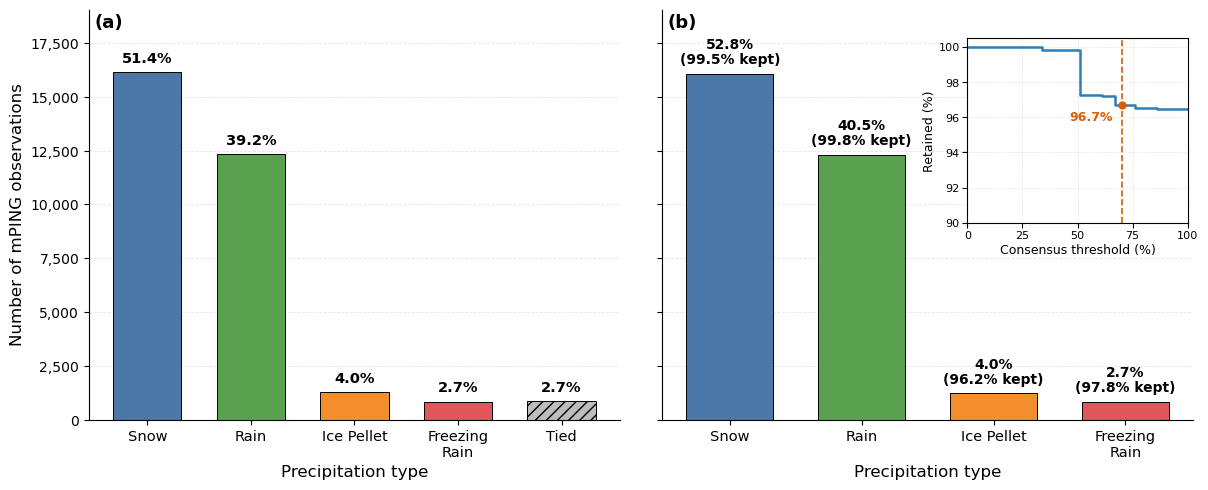

In [9]:
# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
MPING_PATH = ("/glade/campaign/cisl/aiml/ai2es/winter_ptypes/ptype_qc/"
              "mPING_hourafter_interpolated_QC3.parquet")

START = "2021-12-01"            # inclusive
END = "2022-04-01"              # exclusive -> last valid time 2022-03-31 18Z
SYNOPTIC_HOURS = (0, 6, 12, 18)
CONSENSUS_THRESHOLD = 70        # percent

PTYPE_COLS = {                  # column -> label; order = plotting order
    "sn_percent": "Snow",
    "ra_percent": "Rain",
    "pl_percent": "Ice Pellet",
    "fzra_percent": "Freezing Rain",
}
CLASS_ORDER = list(PTYPE_COLS.values())
TIED = "Tied"


PTYPE_COLORS = {
    "Snow":  "#4C78A8",
    "Rain": "#59A14F",
    "Ice Pellet": "#F28E2B",
    "Freezing Rain": "#E15759",
    TIED: "#BDBDBD",
}


# ---------------------------------------------------------------------------
# Data preparation
# ---------------------------------------------------------------------------
def load_mping(path=MPING_PATH, start=START, end=END, hours=SYNOPTIC_HOURS):
    """Load mPING observations for the verification period and valid hours.

    Class fractions are returned on a 0-100 scale regardless of how they are
    stored. Pass hours=None to keep all 24 hours.
    """
    cols = ["datetime", "lat", "lon", "report_count", *PTYPE_COLS]
    df = pd.read_parquet(path, columns=cols)
    df["datetime"] = pd.to_datetime(df["datetime"])

    mask = (df["datetime"] >= start) & (df["datetime"] < end)
    if hours is not None:
        mask &= df["datetime"].dt.hour.isin(hours)
    df = df.loc[mask].copy()

    pct = list(PTYPE_COLS)
    df[pct] = df[pct].fillna(0.0)
    if df[pct].to_numpy().max() <= 1.0:      # stored as fractions
        df[pct] *= 100.0

    # Sanity check: fractions should sum to 100 in every observation
    bad = ~np.isclose(df[pct].sum(axis=1), 100.0, atol=0.5)
    if bad.any():
        print(f"Warning: {bad.sum():,} observations with class fractions "
              "not summing to 100%.")
    return df.reset_index(drop=True)


def assign_dominant_class(df):
    """Add obs_class (dominant ptype, or 'Tied') and obs_consensus (0-100).

    An observation is 'Tied' when two or more classes share the maximum
    fraction (e.g. 50/50); no class is chosen arbitrarily.
    """
    out = df.copy()
    pct = out[list(PTYPE_COLS)].round(6)     # guard float noise (2/3 etc.)
    vmax = pct.max(axis=1)
    n_at_max = pct.eq(vmax, axis=0).sum(axis=1)

    out["obs_consensus"] = vmax
    out["obs_class"] = pct.idxmax(axis=1).map(PTYPE_COLS)
    out.loc[n_at_max > 1, "obs_class"] = TIED
    return out


def apply_consensus_filter(df, threshold=CONSENSUS_THRESHOLD):
    """Keep observations whose dominant class has >= threshold consensus."""
    keep = (df["obs_consensus"] >= threshold) & (df["obs_class"] != TIED)
    return df.loc[keep].copy()


# ---------------------------------------------------------------------------
# Summaries
# ---------------------------------------------------------------------------
def class_distribution(df, include_tied=False):
    """Observation counts, percent of total, and underlying report counts."""
    order = CLASS_ORDER + ([TIED] if include_tied else [])
    counts = df["obs_class"].value_counts().reindex(order, fill_value=0)
    reports = (df.groupby("obs_class")["report_count"].sum()
                 .reindex(order, fill_value=0))
    return pd.DataFrame({
        "Observations": counts,
        "Percent": 100.0 * counts / counts.sum(),
        "Reports": reports,
    })


def class_retention(before, after):
    """Percent of each class's observations retained by the filter."""
    b = before["obs_class"].value_counts().reindex(CLASS_ORDER, fill_value=0)
    a = after["obs_class"].value_counts().reindex(CLASS_ORDER, fill_value=0)
    return 100.0 * a / b.replace(0, np.nan)


def retention_curve(consensus, thresholds=np.arange(0, 101, 1)):
    """Percent of observations with consensus >= t, for each threshold t."""
    c = np.sort(np.round(np.asarray(consensus, dtype=float), 6))
    n_below = np.searchsorted(c, thresholds, side="left")
    return thresholds, 100.0 * (len(c) - n_below) / len(c)


def print_sample_summary(before, after, threshold=CONSENSUS_THRESHOLD):
    """Numbers for the caption / text."""
    n_b, n_a = len(before), len(after)
    print(f"Valid times: {before['datetime'].nunique():,}")
    print(f"Observations: {n_b:,} ({before['report_count'].sum():,} reports)")
    print(f"Tied observations: {(before['obs_class'] == TIED).sum():,}")
    print(f"Retained at >= {threshold}% consensus: {n_a:,} "
          f"({100 * n_a / n_b:.2f}%; {after['report_count'].sum():,} reports)")
    tbl = class_distribution(before, include_tied=True).join(
        class_distribution(after), rsuffix=" (filtered)")
    tbl["Retained %"] = class_retention(before, after)
    print(tbl.round(2).to_string())


def case_counts(df, valid_time, threshold=CONSENSUS_THRESHOLD):
    """Observation/report counts at one valid time, before and after filter."""
    sub = df[df["datetime"] == pd.Timestamp(valid_time)]
    kept = apply_consensus_filter(sub, threshold)
    return {"observations": len(sub), "reports": int(sub["report_count"].sum()),
            "observations_kept": len(kept),
            "reports_kept": int(kept["report_count"].sum())}


# ---------------------------------------------------------------------------
# Figure
# ---------------------------------------------------------------------------
def _tick(label):
    return label.replace(" ", "\n") if label == "Freezing Rain" else label


def _label_bars(ax, bars, lines, ymax, fontsize=10.5):
    return [ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.02 * ymax, text,
                ha="center", va="bottom", fontsize=fontsize,
                fontweight="bold", linespacing=1.1)
            for bar, text in zip(bars, lines)]


def _style_axis(ax):
    ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.3)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", labelsize=10.5)
    ax.tick_params(axis="y", labelsize=10)


def plot_filter_comparison(before, after, threshold=CONSENSUS_THRESHOLD,
                           figsize=(12, 5.0), savepath=None,
                           inset_height=0.45, inset_top=0.93):
    """(a) all observations by dominant class, incl. ties;
    (b) observations with >= threshold consensus, with per-class retention and
    an inset showing sample retention vs. consensus threshold.

    inset_height : inset frame height as a fraction of panel (b)'s height
                   (None = fill all available space). Capped so the inset
                   never overlaps the bar labels.
    inset_top    : top edge of the inset frame, as a fraction of the panel.
    """
    dist_b = class_distribution(before, include_tied=True)
    dist_a = class_distribution(after)
    kept_pct = class_retention(before, after)
    # Curve over all observations (ties have <= 50% consensus, so they drop
    # out for any threshold above 50%, matching apply_consensus_filter)
    thr, ret = retention_curve(before["obs_consensus"])

    fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=figsize, sharey=True,
                                     gridspec_kw={"wspace": 0.08})
    ymax = dist_b["Observations"].max()
    ylim = 1.18 * ymax
    fmt = FuncFormatter(lambda v, _: f"{int(v):,}")

    # ---- (a) before -------------------------------------------------------
    labels_a = list(dist_b.index)
    bars_a = ax_a.bar([_tick(c) for c in labels_a], dist_b["Observations"], width=0.66,
                      color=[PTYPE_COLORS[c] for c in labels_a],
                      edgecolor="black", linewidth=0.7)
    bars_a[-1].set_hatch("///")
    _label_bars(ax_a, bars_a, [f"{p:.1f}%" for p in dist_b["Percent"]], ymax)
    ax_a.set_ylabel("Number of mPING observations", fontsize=12)

    # ---- (b) after --------------------------------------------------------
    bars_b = ax_b.bar([_tick(c) for c in CLASS_ORDER], dist_a["Observations"], width=0.66,
                      color=[PTYPE_COLORS[c] for c in CLASS_ORDER],
                      edgecolor="black", linewidth=0.7)
    texts_b = _label_bars(ax_b, bars_b,
                [f"{p:.1f}%\n({k:.1f}% kept)"
                 for p, k in zip(dist_a["Percent"], kept_pct)], ymax,
                fontsize=10)

    for ax, tag in ((ax_a, "(a)"), (ax_b, "(b)")):
        _style_axis(ax)
        ax.set_ylim(0, ylim)
        ax.yaxis.set_major_formatter(fmt)
        ax.set_xlabel("Precipitation type", fontsize=12)
        ax.text(0.01, 0.99, tag, transform=ax.transAxes, ha="left",
                va="top", fontsize=13, fontweight="bold")

    # ---- inset: placed in the empty space above the minority-class bars ---
    # The position is measured from the rendered bar labels, so it adapts to
    # the data, and the inset's own tick/axis labels are kept clear of them.
    fig.subplots_adjust(left=0.07, right=0.99, bottom=0.15, top=0.97)
    ins = _place_inset(fig, ax_b, left_of=texts_b[1], above=texts_b[2:],
                       draw=lambda a: _draw_inset(a, thr, ret, threshold),
                       height=inset_height, top=inset_top)

    if savepath:
        fig.savefig(f"{savepath}.pdf", bbox_inches="tight")
        fig.savefig(f"{savepath}.png", dpi=300, bbox_inches="tight")
    return fig, (ax_a, ax_b, ins)


def _draw_inset(ins, thr, ret, threshold):
    """Step curve of sample retention vs. consensus threshold."""
    ins.step(thr, ret, where="post", color="#2C7FB8", linewidth=1.8)
    r_thr = ret[np.searchsorted(thr, threshold)]
    ins.axvline(threshold, color="#D95F02", linestyle="--", linewidth=1.2)
    ins.plot(threshold, r_thr, "o", color="#D95F02", markersize=5, zorder=5)
    ins.annotate(f"{r_thr:.1f}%", xy=(threshold, r_thr), xytext=(-6, -4),
                 textcoords="offset points", ha="right", va="top",
                 fontsize=9, fontweight="bold", color="#D95F02")
    ins.set_xlim(0, 100)
    ins.set_ylim(max(0, 5 * np.floor((ret.min() - 2) / 5)), 100.5)
    ins.set_xticks([0, 25, 50, 75, 100])
    ins.set_xlabel("Consensus threshold (%)", fontsize=9, labelpad=2)
    ins.set_ylabel("Retained (%)", fontsize=9, labelpad=2)
    ins.tick_params(labelsize=8, pad=2)
    ins.grid(linestyle="--", linewidth=0.5, alpha=0.3)


def _place_inset(fig, ax, left_of, above, draw, pad=0.02, top=0.93,
                 right=0.99, height=None):
    """Create an inset in `ax` whose frame AND labels sit right of the
    `left_of` text and above the `above` texts (axes-fraction coords)."""
    renderer = fig.canvas.get_renderer()
    to_ax = ax.transAxes.inverted()
    box = lambda art: art.get_window_extent(renderer).transformed(to_ax)

    x_min = box(left_of).x1 + pad
    y_min = max(box(t).y1 for t in above) + pad

    # Probe inset: measure how far tick/axis labels extend beyond the frame
    probe = ax.inset_axes([x_min, y_min, right - x_min, top - y_min])
    draw(probe)
    frame, deco = box(probe), probe.get_tightbbox(renderer).transformed(to_ax)
    dl, db = frame.x0 - deco.x0, frame.y0 - deco.y0
    probe.remove()

    bottom = y_min + db                      # lowest allowed frame bottom
    if height is not None:
        bottom = max(bottom, top - height)   # shorten from below
    rect = [x_min + dl, bottom, right - x_min - dl, top - bottom]
    ins = ax.inset_axes(rect)
    draw(ins)
    return ins


if __name__ == "__main__":
    obs = assign_dominant_class(load_mping())
    kept = apply_consensus_filter(obs)
    print_sample_summary(obs, kept)
    print(case_counts(obs, "2022-02-03 18:00"))
    plot_filter_comparison(obs, kept, savepath="fig_mping_consensus")
    plt.show()